# Equipe Grupo 1 · Tema 2 — Solução fechada e estabilidade
**PDS (EECP0018) · UFMA · Turma 1 · 2026.2 · Seminário de resolução (P2)**

Integrantes (nome completo · matrícula):
- André Luís Aguiar do Nascimento · 20250071151
- João Pedro Miranda Sousa · 20260001188
- Manoel Lucas Pacheco Junior · 20250071269
- Paulo Eduardo Lima Rabelo · 20260001203
- Antonio Marcos Patrício Castro · 20260035112

**Problema.** Considere $y[n] = a\,y[n-1] + x[n]$, em repouso.
(a) Mostre que $h[n] = a^n u[n]$.
(b) Para $a = 0{,}8$, $a = 1{,}2$ e $a = -0{,}8$, diga se o sistema é estável, justificando com $\sum|h[n]|$.
(c) Simule 30 amostras de $h[n]$ para cada valor de $a$ em Python e mostre os gráficos.

Este notebook confere em Python a resolução feita à mão.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

CASOS = [0.8, 1.2, -0.8]   # valores de a do enunciado
N = 30                     # 30 amostras: n = 0, 1, ..., 29

n = np.arange(N)
delta = (n == 0).astype(float)   # impulso unitário δ[n]

## (a) $h[n]$ por recursão, forma fechada e `lfilter`
A recursão aplica $h[n] = a\,h[n-1] + \delta[n]$ com $h[-1]=0$, exatamente como à mão.
`lfilter(b, a_coef, x)` resolve $\sum a_k y[n-k] = \sum b_k x[n-k]$; reescrevendo $y[n] - a\,y[n-1] = x[n]$, temos `b = [1]` e `a_coef = [1, -a]` (atenção ao sinal).

In [ ]:
def recursao(a, x, y_anterior=0.0):
    """Calcula y[n] = a*y[n-1] + x[n] amostra por amostra, a partir do repouso."""
    y = np.zeros(len(x))
    for k in range(len(x)):
        y[k] = a * y_anterior + x[k]
        y_anterior = y[k]
    return y

for a in CASOS:
    h_rec = recursao(a, delta)
    h_fechada = a**n                       # n >= 0, então u[n] = 1
    h_lf = lfilter([1.0], [1.0, -a], delta)
    print(f"a = {a}")
    print("   n | recursão  | a^n       | lfilter")
    for k in range(5):
        print(f"  {k:2d} | {h_rec[k]: .6f} | {h_fechada[k]: .6f} | {h_lf[k]: .6f}")
    dif = max(np.max(np.abs(h_rec - h_fechada)), np.max(np.abs(h_lf - h_fechada)))
    print(f"  maior diferença entre os métodos (30 amostras): {dif:.2e}\n")

a = 0.8
   n | recursão  | a^n       | lfilter
   0 |  1.000000 |  1.000000 |  1.000000
   1 |  0.800000 |  0.800000 |  0.800000
   2 |  0.640000 |  0.640000 |  0.640000
   3 |  0.512000 |  0.512000 |  0.512000
   4 |  0.409600 |  0.409600 |  0.409600
  maior diferença entre os métodos (30 amostras): 1.11e-16

a = 1.2
   n | recursão  | a^n       | lfilter
   0 |  1.000000 |  1.000000 |  1.000000
   1 |  1.200000 |  1.200000 |  1.200000
   2 |  1.440000 |  1.440000 |  1.440000
   3 |  1.728000 |  1.728000 |  1.728000
   4 |  2.073600 |  2.073600 |  2.073600
  maior diferença entre os métodos (30 amostras): 8.53e-14

a = -0.8
   n | recursão  | a^n       | lfilter
   0 |  1.000000 |  1.000000 |  1.000000
   1 | -0.800000 | -0.800000 | -0.800000
   2 |  0.640000 |  0.640000 |  0.640000
   3 | -0.512000 | -0.512000 | -0.512000
   4 |  0.409600 |  0.409600 |  0.409600
  maior diferença entre os métodos (30 amostras): 5.55e-17



## (b) Estabilidade pela soma $\sum|h[n]|$
Com $h[n]=a^n u[n]$: $\sum_{n=0}^{\infty}|h[n]| = \sum |a|^n$, série geométrica.
Converge para $1/(1-|a|)$ se $|a|<1$; diverge se $|a|\ge 1$. Abaixo, as somas parciais $S_M = \sum_{n=0}^{M}|a|^n$.

In [ ]:
for a in CASOS:
    S = {M: np.sum(np.abs(a)**np.arange(M + 1)) for M in [10, 29, 100]}
    if abs(a) < 1:
        teoria = f"1/(1-|a|) = {1/(1-abs(a)):.4g}  ->  ESTÁVEL"
    else:
        teoria = "diverge  ->  INSTÁVEL"
    print(f"a = {a:>4}: S_10 = {S[10]:.4g} | S_29 = {S[29]:.4g} | S_100 = {S[100]:.4g} | {teoria}")

a =  0.8: S_10 = 4.571 | S_29 = 4.994 | S_100 = 5 | 1/(1-|a|) = 5  ->  ESTÁVEL
a =  1.2: S_10 = 32.15 | S_29 = 1182 | S_100 = 4.969e+08 | diverge  ->  INSTÁVEL
a = -0.8: S_10 = 4.571 | S_29 = 4.994 | S_100 = 5 | 1/(1-|a|) = 5  ->  ESTÁVEL


## (c) 30 amostras de $h[n]$ para cada valor de $a$

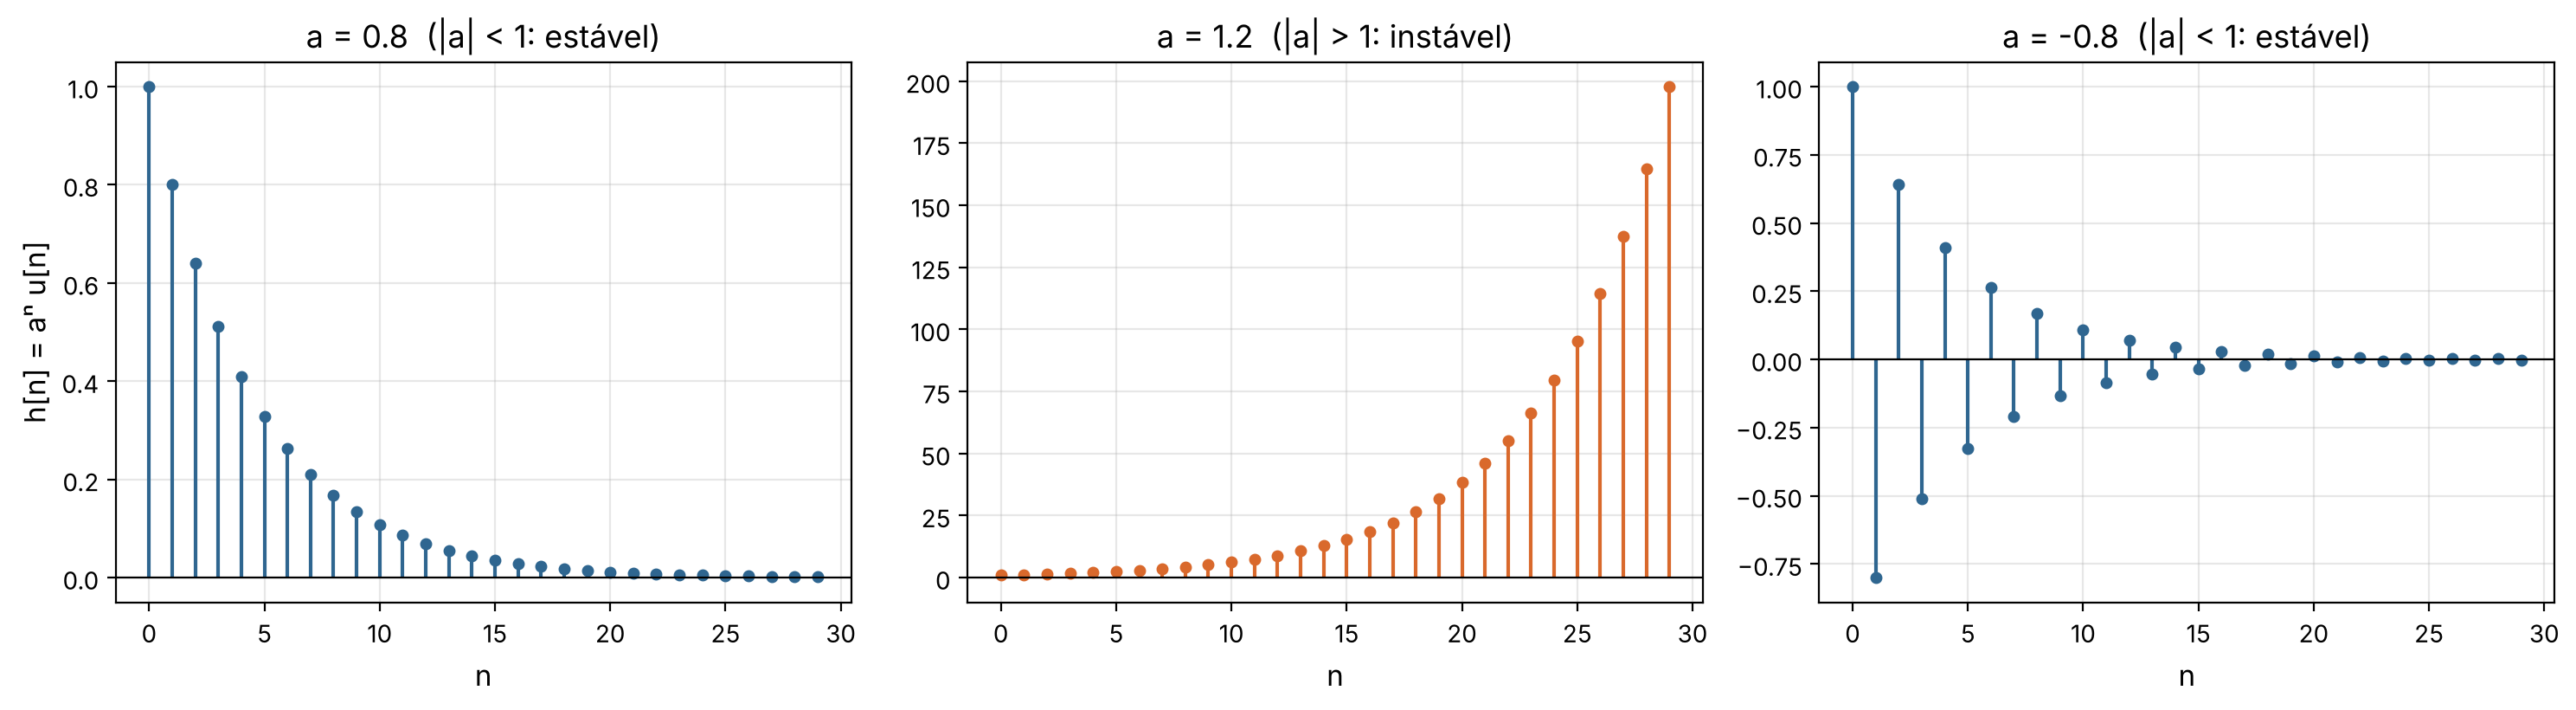

h[29] para cada a: {0.8: 0.0015, 1.2: 197.8136, -0.8: -0.0015}


In [ ]:
cores = ['#2F6690', '#D9692C', '#2F6690']
rotulos = ['|a| < 1: estável', '|a| > 1: instável', '|a| < 1: estável']
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, a, cor, rot in zip(axs, CASOS, cores, rotulos):
    h = a**n
    ml, sl, bl = ax.stem(n, h, basefmt=' ')
    plt.setp(ml, color=cor, markersize=4); plt.setp(sl, color=cor)
    ax.axhline(0, color='k', lw=0.8)
    ax.set_title(f"a = {a}  ({rot})", fontsize=13)
    ax.set_xlabel('n', fontsize=12)
    ax.grid(alpha=0.3)
axs[0].set_ylabel('h[n] = aⁿ u[n]', fontsize=12)
plt.tight_layout()
plt.savefig('fig_h_enunciado.png', dpi=200)
plt.show()

print("h[29] para cada a:", {a: round(a**29, 4) for a in CASOS})

## Complemento: o que $\sum|h[n]| = 5$ garante (a = 0,8)
Com entrada degrau ($|x[n]|\le 1$), $s[n] = \sum_{k=0}^{n} 0{,}8^k = (1-0{,}8^{n+1})/0{,}2 \to 5$: a saída fica abaixo de $5 \cdot 1$.

In [ ]:
s = lfilter([1.0], [1.0, -0.8], np.ones(N))
s_fech = (1 - 0.8**(n + 1)) / 0.2
print("s[0..3] =", np.round(s[:4], 4), "| s[29] =", round(s[-1], 4), "| confere:", np.allclose(s, s_fech))

s[0..3] = [1.    1.8   2.44  2.952] | s[29] = 4.9938 | confere: True


## Erro comum: esquecer o módulo em $\sum|h[n]|$ (ou julgar pelo sinal de $a$)
- $a=-0{,}8$: $h[n]$ troca de sinal, mas $\sum|h[n]| = 5$, logo é estável.
- $a=-1$: sem o módulo, as somas parciais de $h[n]$ ficam 1, 0, 1, 0, … (limitadas e enganosas); com o módulo, $\sum|h[n]|=\infty$ e o sistema é instável.

In [ ]:
h_m1 = (-1.0)**n
print("a = -1: somas parciais SEM módulo:", np.cumsum(h_m1)[:8])
print("a = -1: somas parciais COM módulo:", np.cumsum(np.abs(h_m1))[:8])

# entrada limitada x[n] = (-1)^n no sistema com a = -1: a saída cresce
y = lfilter([1.0], [1.0, 1.0], (-1.0)**n)
print("a = -1, x[n] = (-1)^n  ->  y[0..7] =", y[:8])

a = -1: somas parciais SEM módulo: [1. 0. 1. 0. 1. 0. 1. 0.]
a = -1: somas parciais COM módulo: [1. 2. 3. 4. 5. 6. 7. 8.]
a = -1, x[n] = (-1)^n  ->  y[0..7] = [ 1. -2.  3. -4.  5. -6.  7. -8.]


## Conclusão
- Recursão, forma fechada $a^n u[n]$ e `lfilter` coincidem nas 30 amostras (diferenças só de arredondamento).
- $a = 0{,}8$: $\sum|h[n]| = 5$ → **estável**.
- $a = 1{,}2$: $\sum|h[n]|$ diverge → **instável**.
- $a = -0{,}8$: $\sum|h[n]| = 5$ → **estável** (oscila, mas $|a|<1$).